# AI Deaf Companion: Data Cleaning & Exploratory Data Analysis

Dataset: **Sign Language MNIST** (OpenML id 45082) — 28×28 grayscale images of American Sign Language hand gestures for 24 letters (J and Z need motion and are excluded). 27,455 training and 7,172 test images.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.data import LETTERS, IMG_SIZE, load_raw, clean, split, balance, to_xy
sns.set_theme(style='whitegrid')

## 1. Load raw data

In [2]:
raw = load_raw()
print(raw.shape)
raw.iloc[:5, :8]

(34627, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7
0,3,107,118,127,134,139,143,146
1,6,155,157,156,156,156,157,156
2,2,187,188,188,187,187,186,187
3,2,211,211,212,212,211,210,211
4,13,164,167,170,172,176,179,180


## 2. Data quality checks & cleaning
We check for missing pixel values, out-of-range intensities and exact duplicate rows. Missing pixels are filled with the column median, values are clipped to 0–255 and duplicates dropped.

In [3]:
print('Missing values per column (top 5):')
print(raw.isna().sum().sort_values(ascending=False).head())
df, stats = clean(raw)
stats

Missing values per column (top 5):
label     0
pixel1    0
pixel2    0
pixel3    0
pixel4    0
dtype: int64


{'rows_in': 34627,
 'missing_values': 0,
 'out_of_range_values': 0,
 'duplicates': 0,
 'rows_out': 34627}

In [4]:
raw.drop(columns='label').stack().describe()

count    2.714757e+07
mean     1.595562e+02
std      4.882894e+01
min      0.000000e+00
25%      1.300000e+02
50%      1.680000e+02
75%      1.940000e+02
max      2.550000e+02
dtype: float64

## 3. Class distribution
The training classes are not equal in size, so the training split is upsampled to the largest class to avoid biasing the classifier.

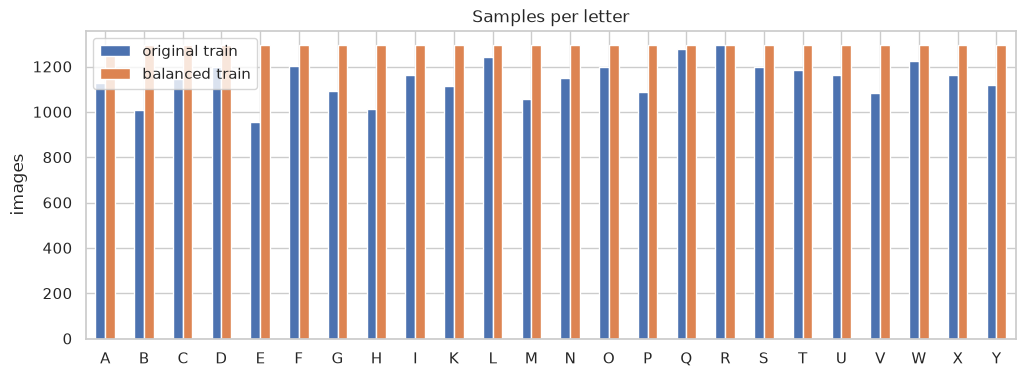

imbalance ratio (max/min) before: 1.35 after: 1.0


In [5]:
train, test = split(df)
balanced = balance(train)
counts = pd.DataFrame({'original train': train['label'].value_counts(), 'balanced train': balanced['label'].value_counts(), 'test': test['label'].value_counts()}).sort_index()
counts.index = [LETTERS[i] for i in counts.index]
ax = counts[['original train', 'balanced train']].plot.bar(figsize=(12, 4), rot=0, title='Samples per letter')
ax.set_ylabel('images'); plt.show()
print('imbalance ratio (max/min) before:', round(train['label'].value_counts().max() / train['label'].value_counts().min(), 2), 'after:', round(balanced['label'].value_counts().max() / balanced['label'].value_counts().min(), 2))

## 4. Sample gestures per letter

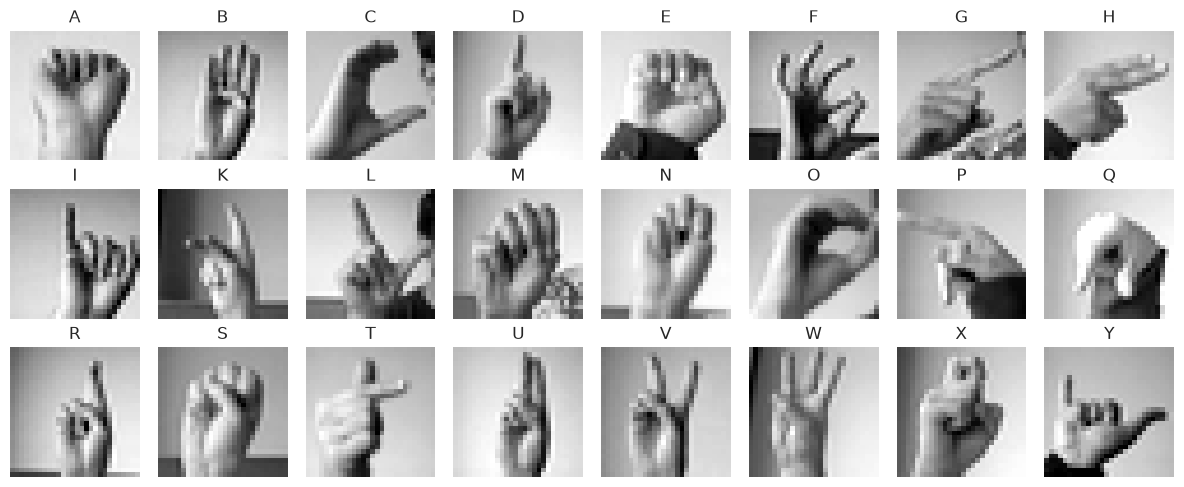

In [6]:
X, y = to_xy(train)
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, code in zip(axes.flat, sorted(LETTERS)):
    ax.imshow(X[np.flatnonzero(y == code)[0]].reshape(IMG_SIZE, IMG_SIZE), cmap='gray'); ax.set_title(LETTERS[code]); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Average gesture per letter
Mean images show the typical hand shape; similar shapes (e.g. M/N, U/V/R) hint at which letters the model may confuse.

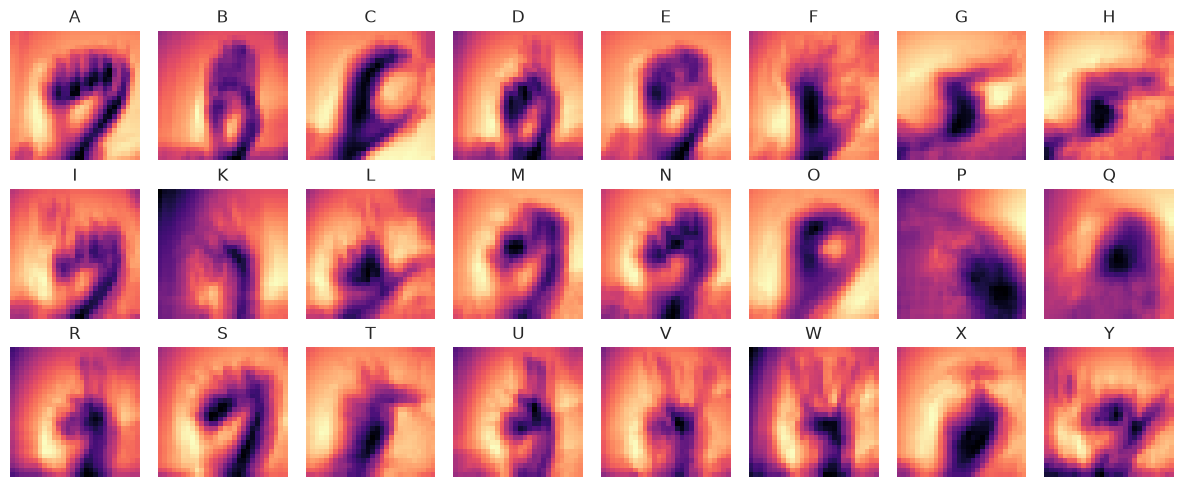

In [7]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, code in zip(axes.flat, sorted(LETTERS)):
    ax.imshow(X[y == code].mean(axis=0).reshape(IMG_SIZE, IMG_SIZE), cmap='magma'); ax.set_title(LETTERS[code]); ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Pixel intensity distribution

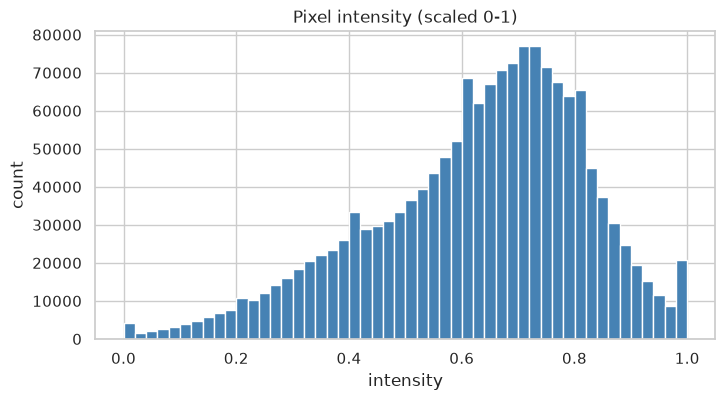

In [8]:
plt.figure(figsize=(8, 4)); plt.hist(X[:2000].ravel(), bins=50, color='steelblue'); plt.title('Pixel intensity (scaled 0-1)'); plt.xlabel('intensity'); plt.ylabel('count'); plt.show()

## 7. Model results
Produced by `python -m src.train` (Logistic Regression, Random Forest and SVM compared on precision, recall and F1).

In [9]:
pd.read_csv('../reports/metrics.csv')

,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds
0,logistic_regression,0.6842,0.6743,0.6719,0.6616,16.3
1,random_forest,0.8238,0.8171,0.8145,0.8083,11.1
2,svm_rbf,0.8695,0.8581,0.8622,0.8550,9.4


In [10]:
print(open('../reports/classification_report.txt').read())

Best model: svm_rbf

              precision    recall  f1-score   support

           A      0.930     1.000     0.964       331
           B      1.000     1.000     1.000       432
           C      0.870     0.990     0.926       310
           D      0.961     0.996     0.978       245
           E      0.960     1.000     0.979       498
           F      0.839     0.862     0.850       247
           G      0.931     0.894     0.912       348
           H      0.969     0.920     0.944       436
           I      0.836     0.924     0.878       288
           K      0.823     0.674     0.741       331
           L      0.852     0.990     0.916       209
           M      0.929     0.792     0.855       394
           N      0.914     0.763     0.831       291
           O      0.969     0.886     0.926       246
           P      1.000     1.000     1.000       347
           Q      0.937     1.000     0.968       164
           R      0.394     0.618     0.481       144
      

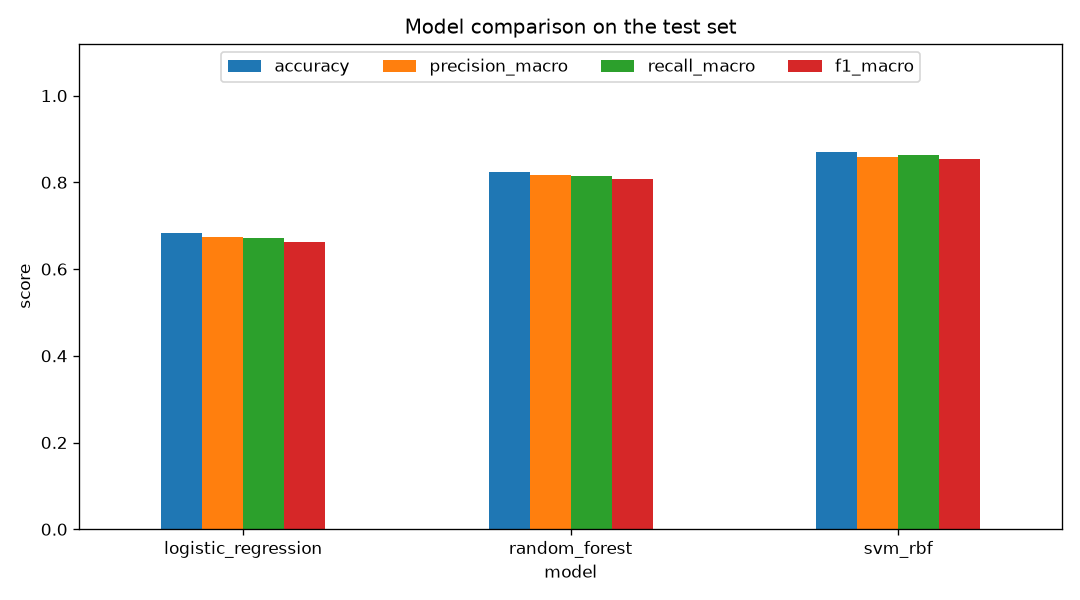

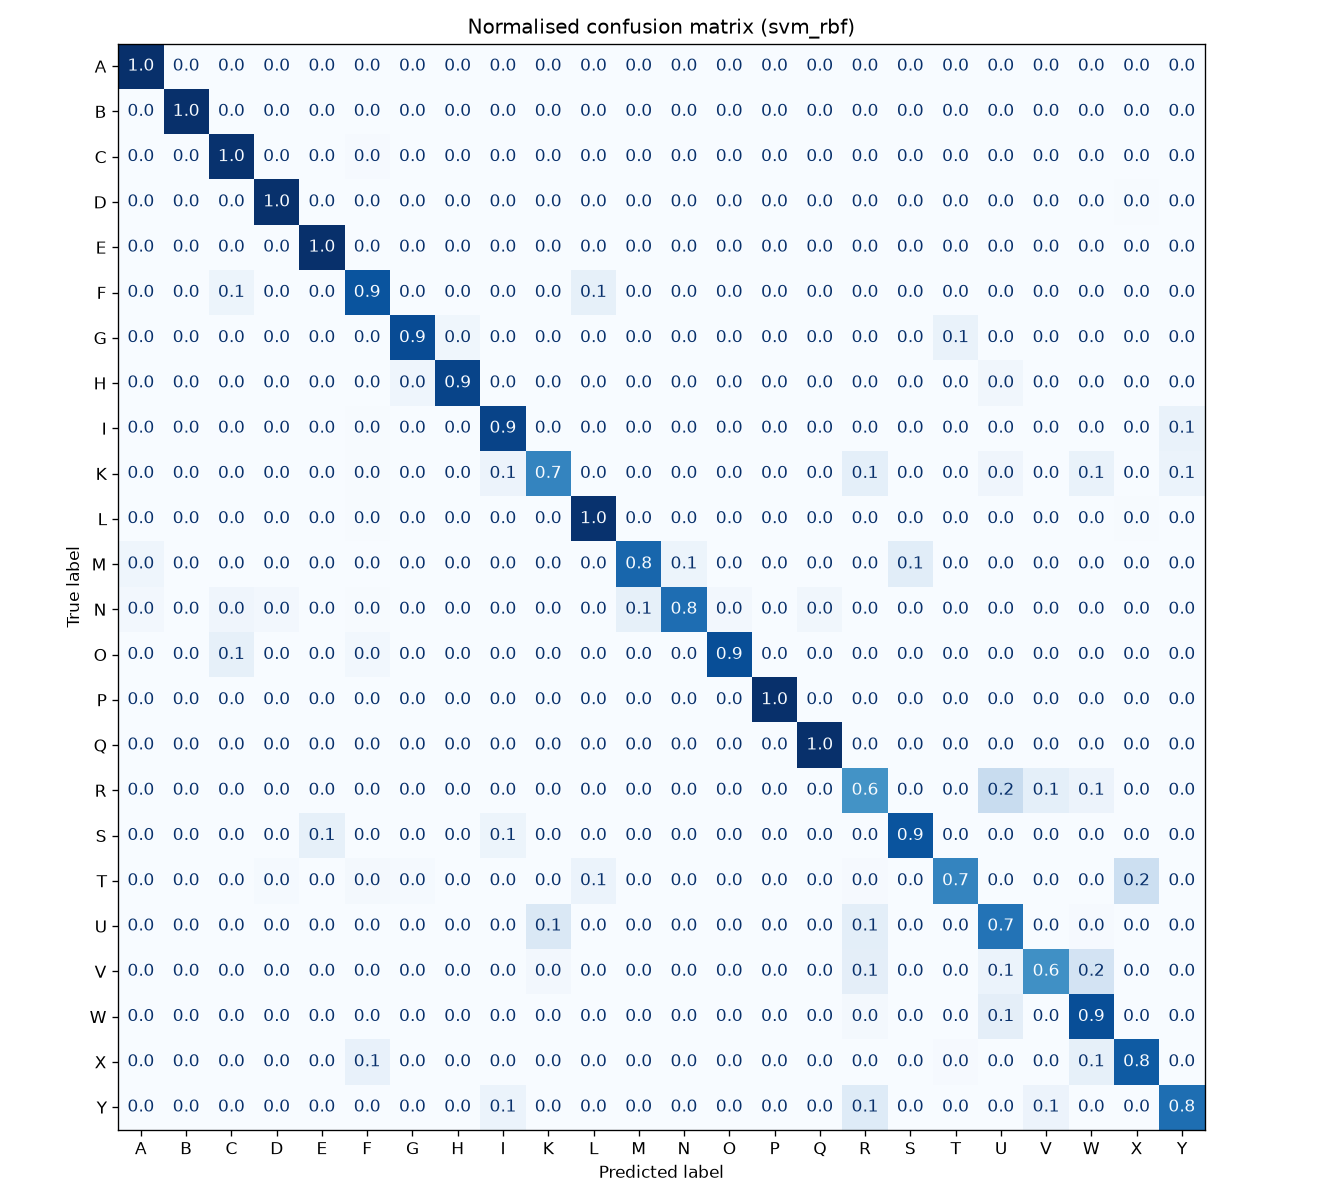

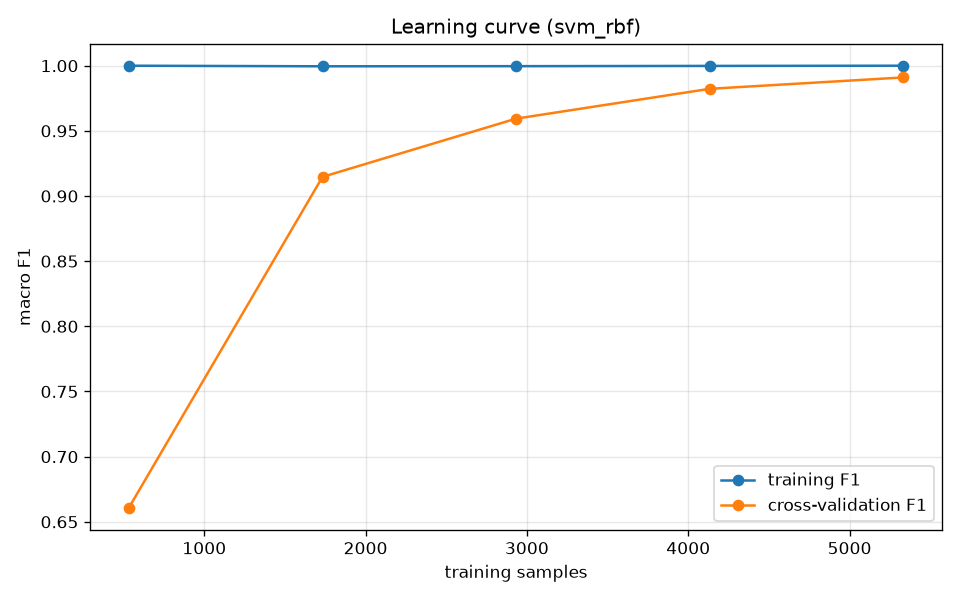

In [11]:
from IPython.display import Image, display
for f in ['model_comparison.png', 'confusion_matrix.png', 'learning_curve.png']:
    display(Image(filename=f'../reports/{f}'))